In [1]:
import numpy as np
import matplotlib.pyplot as plt
import csv

In [2]:
# load the data set: we must load the dataset into a 2D numpy array
file_path = "C:\\Users\\eacar\\OneDrive\\Desktop\\GitFork_3.0\\Multiple-Linear-Regression\\data\\Student_Performance.csv"
array = []
with open(file_path, "r") as file:
    content = csv.reader(file) # loads as a string
    next(content) # skip the header row
    for row in content:
        add_row = []
        for val in row:
            # change bool values to numerical representations
            if val == "Yes":
                add_row.append(1)
                continue
            elif val == "No":
                add_row.append(0)
                continue
            # add all values as an integer
            add_row.append(int(float(val)))
        array.append(add_row)

# turn into a numpy array for further efficient manipulation
array = np.array(array)
# create the x and y vectors as numpy arrays
vec_x = np.array(array[:, :-1])
vec_y = np.array(array[:, -1:])
# Make vec_y a 1D array
vec_y = vec_y.flatten()
print(vec_x)
print(vec_y)

[[ 7 99  1  9  1]
 [ 4 82  0  4  2]
 [ 8 51  1  7  2]
 ...
 [ 6 83  1  8  5]
 [ 9 97  1  7  0]
 [ 7 74  0  8  1]]
[91 65 45 ... 74 95 64]


In [3]:
# Feature scaling (Z-score normalization)
n = vec_x.shape[1]
vec_x_copy = np.zeros((vec_x.shape[0], vec_x.shape[1]))

for j in range(n):
    # Skip binary 0/1 columns - keeps weights easy to interpret
    if set(np.unique(vec_x[:, j])).issubset({0, 1}):
        # Copy all 1/0 rows over to the copy-array x
        vec_x_copy[:,j] += vec_x[:,j]
        continue
    # Calculate mean and variance per column
    mean_x = np.mean(vec_x[:,j])
    std_x = np.std(vec_x[:,j])
    # Scale for each feature row:
    vec_x_copy[:, j] = (vec_x[:,j] - mean_x) / std_x
# Re-initialize inputs to the scaled version
vec_x = np.copy(vec_x_copy)
print(vec_x)
# You can increase your alpha rate for a more efficient drop of cost, due to feature scaling

[[ 0.77518771  1.70417565  1.          1.45620461 -1.24975394]
 [-0.38348058  0.72391268  0.         -1.49229423 -0.90098215]
 [ 1.16141048 -1.06362569  1.          0.27680507 -0.90098215]
 ...
 [ 0.38896495  0.7815752   1.          0.86650484  0.1453332 ]
 [ 1.54763324  1.5888506   1.          0.27680507 -1.59852572]
 [ 0.77518771  0.26261245  0.          0.86650484 -1.24975394]]


In [4]:
# Declare and initialize weights as zeros
vec_w = np.zeros(vec_x.shape[1])
b = 0.0

In [5]:
# Sum vectorization tip:
# np.sum(a, axis=None, dtype=None, out=None, keepdims=False, initial=0, where=True) 
# axis = The dimension to collapse during the sum (None sums all elements, 0 sums down rows, 1 sums across column).

def compute_gradient(vec_w, vec_x, vec_y, b):
    iterations = 1500
    alpha = 0.01 # lower the alpha so that gradient doesn't diverge (it will bounce dramatically)
    m = vec_x.shape[0]
    for iteration in range(iterations):
        # Compute simultaneuous weight calculations
        f_wb = vec_x @ vec_w + b
        # Sum the array of each -> x[j]^[i] * (y_hat - y) for all rows, across each column (with numpy naturally)
        total_sum_w = np.sum(((f_wb - vec_y).reshape(-1, 1) * vec_x), 0) # we reshape so that we can broadcast and perform aligned computation
        difference_w = alpha * (total_sum_w/m)
        vec_w = vec_w - difference_w
        
        # Compute for B value
        total_sum_b = np.sum(f_wb - vec_y)
        difference_b = alpha * (total_sum_b/m) 
        b = b - difference_b

    return vec_w, b

# Initialize the new weights
vec_w, b = compute_gradient(vec_w, vec_x, vec_y, b)

print("Calculated weights:", vec_w)
print("Calculated bias:", b)

Calculated weights: [ 7.38373166 17.65487266  1.96748785  0.83454187  0.54473395]
Calculated bias: 54.09235641362546


In [6]:
# We pass two 2D numpy arrays as the arguments
def compute_model_output(vec_w, vec_x, b):
    f_wb = vec_x @ vec_w + b
    # Return the 2D numpy array
    return f_wb

f_wb = compute_model_output(vec_w, vec_x, b)
print(f"Model output (y-hat): {f_wb}")

Model output (y-hat): [92.4051068  62.30524721 45.59742125 ... 73.53277027 94.89834201
 64.49487504]


In [7]:
def cost_funtion(vec_w, vec_x, vec_y, b):
    # Declare arrayed-variables 
    m = vec_x.shape[0]
    # Perform vectorized-computation (thankfully numpy helps with this)
    f_wb = vec_x @ vec_w + b
    cost = np.sum((f_wb - vec_y)**2)
    computation = (1/(2 * m)) * cost
    return computation

print(f"Cost: {cost_funtion(vec_w, vec_x, vec_y, b)}")

Cost: 2.3174710000269183


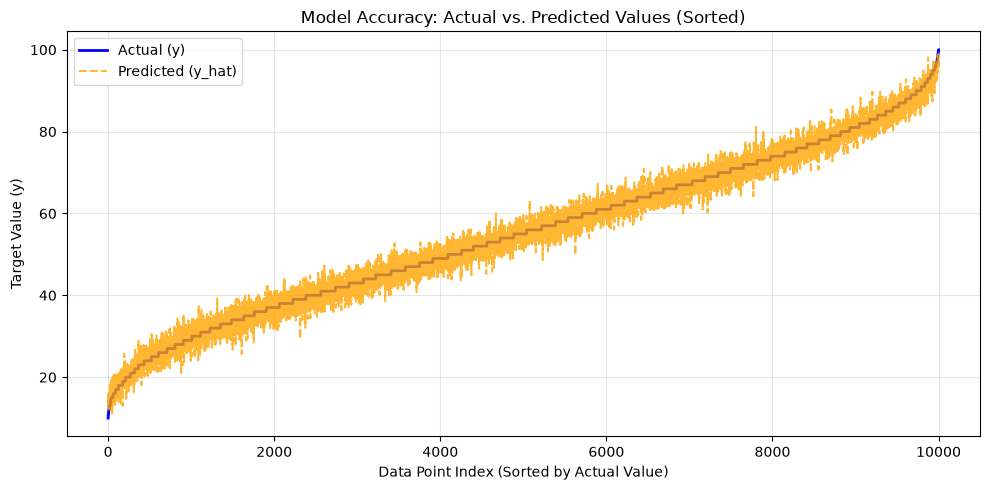

In [8]:
# 1. argsort sorts down the 10,000 values properly
sorted_indices = np.argsort(vec_y)
y_sorted = vec_y[sorted_indices]
y_hat_sorted = f_wb[sorted_indices]

# 2. Create the x-axis (sample index 0, 1, 2, ... m-1)
sample_index = np.arange(len(vec_y))

# 3. Plot both lines
plt.figure(figsize=(10, 5))
plt.plot(sample_index, y_sorted, label='Actual (y)', color='blue', linewidth=2)
plt.plot(sample_index, y_hat_sorted, label='Predicted (y_hat)', color='orange', linestyle='--', alpha=0.8)

# 4. Formatting
plt.title('Model Accuracy: Actual vs. Predicted Values (Sorted)')
plt.xlabel('Data Point Index (Sorted by Actual Value)')
plt.ylabel('Target Value (y)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
